# 04 — Supervised + Unsupervised Integration

## SIADS 696 Milestone II

This notebook connects Part A (`02_supervised_learning.ipynb`) and Part B
(`03_unsupervised_learning.ipynb`).

### Question

Does the institutional structure discovered by clustering contain predictive
information about debt burden beyond the original institutional
characteristics?

### Inputs

| From | Output used here |
|---|---|
| `02_supervised_learning.ipynb` | Selected model and tuned hyperparameters (`results/02_supervised/selected_model.json`), shared outer folds (`cv_folds.csv`), Lasso hyperparameters (`tuned_hyperparameters.json`) |
| `03_unsupervised_learning.ipynb` | Selected clustering configuration (`results/03_unsupervised/selected_clustering.json`) and the reusable cluster-feature pipeline in `src/unsupervised.py` |

### Approach

1. Rebuild the selected LightGBM model with its tuned hyperparameters and
   confirm it reproduces the Part A cross-validation score on the saved folds.
2. Add cluster-derived features (one-hot membership and centroid distances)
   with the unsupervised pipeline **refit inside every training fold**, and
   compare RMSE, MAE, and R² fold by fold against the supervised model alone.
3. Check variants: membership only, distances only, PCA scores, and the
   number of clusters k.
4. Check whether a linear model, which cannot build interactions itself,
   benefits more from the cluster features.
5. Repeat the main comparison over several random fold assignments.
6. Examine where (sector, degree level, cluster) the cluster features change
   the errors, and how much the model uses them.
7. Record the pipeline to carry into `05_final_evaluation.ipynb`.

### Decision Rule

Following the project timeline, cluster features are adopted only if the
RMSE improvement is **larger than the fold-to-fold variation**: the mean
paired improvement must exceed the standard deviation of the per-fold
differences, and the integrated model must win in a clear majority of
folds. Otherwise the simpler supervised model is kept.

Only the **training set** is used. The held-out test set is not loaded.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, PredefinedSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Project directories
PROJECT_ROOT = Path("..")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SUPERVISED_DIR = PROJECT_ROOT / "results" / "02_supervised"
UNSUPERVISED_DIR = PROJECT_ROOT / "results" / "03_unsupervised"
FIGURES_DIR = PROJECT_ROOT / "figures" / "04_integration"
RESULTS_DIR = PROJECT_ROOT / "results" / "04_integration"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Shared components from the supervised and unsupervised analyses
sys.path.insert(0, str(PROJECT_ROOT.resolve()))
from src.unsupervised import clustering_columns
from src.integration import (
    ClusterMeanRegressor,
    make_integrated_model,
    make_lgbm,
    make_unsupervised_block,
)

SECTOR_LABELS = {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
SECTOR_ORDER = list(SECTOR_LABELS.values())
PREDDEG_LABELS = {1: "Certificate", 2: "Associate", 3: "Bachelor's", 4: "Graduate"}
DEGREE_ORDER = list(PREDDEG_LABELS.values())

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# LightGBM warns when feature names are dropped by an upstream transformer.
warnings.filterwarnings("ignore", message="X does not have valid feature names")


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the Training Data and Earlier Decisions

The selected supervised model, its hyperparameters, and the outer folds come
from `02_supervised_learning.ipynb`; the clustering settings come from
`03_unsupervised_learning.ipynb`. Nothing is re-tuned here, so any change in
score is due to the added features.

In [2]:
with open(SUPERVISED_DIR / "selected_model.json") as f:
    supervised = json.load(f)
with open(SUPERVISED_DIR / "tuned_hyperparameters.json") as f:
    tuned_params = json.load(f)
with open(UNSUPERVISED_DIR / "selected_clustering.json") as f:
    clustering = json.load(f)

train = pd.read_csv(PROCESSED_DIR / "train_dataset.csv")
cv_folds = pd.read_csv(SUPERVISED_DIR / "cv_folds.csv")

ID_COL = "OPEID6"
TARGET = supervised["target"]
FEATURES = supervised["features"]
CATEGORICAL_FEATURES = supervised["categorical_features"]
LOG_COLS = supervised["log_features"]
NUMERIC_FEATURES = [c for c in FEATURES if c not in CATEGORICAL_FEATURES + LOG_COLS]
CLUSTER_COLS = clustering_columns(train)
SELECTED_K = clustering["n_clusters"]
PCA_VARIANCE = clustering["pca_variance"]
RANDOM_STATE = clustering["random_state"]
N_FOLDS = supervised["cv"]["n_splits"]
CLUSTER_NAMES = {int(k): v for k, v in clustering["cluster_names"].items()}

X = train[FEATURES]
y = train[TARGET]

# The folds must line up row for row with the training set.
assert (cv_folds[ID_COL].to_numpy() == train[ID_COL].to_numpy()).all()
fold_id = cv_folds["fold"].to_numpy()
OUTER_CV = PredefinedSplit(fold_id)

# The clustering columns are a subset of the supervised features, and neither
# set contains the identifier or the target.
assert set(CLUSTER_COLS) <= set(FEATURES)
assert ID_COL not in FEATURES + CLUSTER_COLS and TARGET not in FEATURES + CLUSTER_COLS

train["SECTOR"] = train["CONTROL"].map(SECTOR_LABELS)
train["DEGREE"] = train["PREDDEG"].map(PREDDEG_LABELS)

print("Training institutions:", len(train))
print(f"Selected supervised model: {supervised['model']}  "
      f"(nested-CV RMSE {supervised['nested_cv_rmse_mean']:.4f})")
print("Hyperparameters:", {k: round(v, 4) for k, v in supervised["hyperparameters"].items()})
print(f"Supervised features: {len(FEATURES)}")
print(f"Clustering input columns: {len(CLUSTER_COLS)} (all features except CONTROL and REGION)")
print(f"Selected clustering: {clustering['method']}, k = {SELECTED_K}, "
      f"PCA {PCA_VARIANCE:.0%} variance")
print("Validation institutions per fold:", np.bincount(fold_id).tolist())

Training institutions: 2636
Selected supervised model: LightGBM  (nested-CV RMSE 0.2741)
Hyperparameters: {'colsample_bytree': 0.4306, 'learning_rate': 0.0056, 'min_child_samples': 29, 'n_estimators': 963, 'num_leaves': 39, 'reg_lambda': 0.0012, 'subsample': 0.756}
Supervised features: 35
Clustering input columns: 33 (all features except CONTROL and REGION)
Selected clustering: k-means, k = 4, PCA 85% variance
Validation institutions per fold: [528, 527, 527, 527, 527]


## 2. Leakage-Safe Integration Pipeline

The cluster features are produced by the same filter → impute → scale →
PCA → k-means pipeline selected in `03_unsupervised_learning.ipynb`. It sits
*inside* the model pipeline as one branch of a `ColumnTransformer`:

```
            ┌─ passthrough: 35 supervised features ───────────────┐
raw rows ───┤                                                     ├─→ LightGBM
            └─ 33 clustering columns → filter → impute → scale →  │
                 PCA → k-means → one-hot membership + distances ──┘
```

Calling `fit` on a training fold therefore fits the column filter, imputer,
scaler, PCA, and k-means on that fold only; validation rows are assigned to
the nearest training centroid. `debt_burden` never enters the unsupervised
branch.

The cluster labels in `results/03_unsupervised/train_cluster_assignments.csv`
were fit on the full training set and are **not** used as model features;
they are used only to group errors in Section 8.

The check below fits the pipeline on one training fold and shows the design
matrix it produces.

In [3]:
train_idx, valid_idx = next(OUTER_CV.split(X))
demo = make_integrated_model(make_lgbm(supervised["hyperparameters"]), FEATURES, CLUSTER_COLS,
                             block="membership+distances", n_clusters=SELECTED_K,
                             pca_variance=PCA_VARIANCE, random_state=RANDOM_STATE)
demo.fit(X.iloc[train_idx], y.iloc[train_idx])

unsup = demo.named_steps["features"].named_transformers_["unsupervised"]
fold_filter = unsup.named_steps["filter"]
fold_pca = unsup.named_steps["pca"]
design = demo.named_steps["features"].transform(X.iloc[valid_idx])

print("Fold 0 training rows:", len(train_idx), "| validation rows:", len(valid_idx))
print("Columns dropped by the fold's filter:", fold_filter.dropped_)
print(f"PCA components fit on the fold: {fold_pca.n_components_} "
      f"({fold_pca.explained_variance_ratio_.sum():.1%} of variance)")
print("Design matrix shape (validation rows):", design.shape,
      f"= {len(FEATURES)} supervised + {design.shape[1] - len(FEATURES)} cluster features")
print("Validation cluster sizes:", np.bincount(design[:, len(FEATURES):len(FEATURES) + SELECTED_K]
                                              .argmax(axis=1)).tolist())

Fold 0 training rows: 2108 | validation rows: 528
Columns dropped by the fold's filter: {'ADM_RATE': 'missing 54%', 'SAT_AVG': 'missing 65%', 'TUITIONFEE_IN': '|r| = 0.946 with COST_OF_ATTENDANCE', 'HIGHDEG': '|r| = 0.906 with PREDDEG'}
PCA components fit on the fold: 13 (85.7% of variance)
Design matrix shape (validation rows): (528, 43) = 35 supervised + 8 cluster features
Validation cluster sizes: [133, 126, 143, 126]


**The pipeline behaves as intended inside a fold.** Fit on the 2,108 training rows of fold 0, the filter drops the same four columns as in Part B (`ADM_RATE`, `SAT_AVG`, `TUITIONFEE_IN`, `HIGHDEG`), PCA keeps 13 components (85.7% of variance), and the 528 validation institutions are spread across all four clusters. Each validation row reaches LightGBM with 43 columns: the 35 supervised features plus 4 membership indicators and 4 centroid distances.

## 3. Evaluation Helper

Every candidate is evaluated with `cross_validate` on the shared outer folds,
recording per-fold RMSE, MAE, and R² and the out-of-fold predictions.

In [4]:
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

cv_scores = []
oof_predictions = {}
fitted_models = {}


def evaluate(name, estimator, cv=OUTER_CV, record=True):
    start = time.time()
    result = cross_validate(estimator, X, y, cv=cv, scoring=SCORING, return_estimator=True)
    folds = pd.DataFrame({
        "model": name,
        "fold": np.arange(len(result["test_rmse"])),
        "rmse": -result["test_rmse"],
        "mae": -result["test_mae"],
        "r2": result["test_r2"],
    })
    if record:
        oof = np.empty(len(y))
        for est, (_, idx) in zip(result["estimator"], cv.split(X)):
            oof[idx] = est.predict(X.iloc[idx])
        oof_predictions[name] = oof
        fitted_models[name] = result["estimator"]
        cv_scores.append(folds)
    print(f"{name:<42} RMSE {folds['rmse'].mean():.4f} ± {folds['rmse'].std():.4f}   "
          f"MAE {folds['mae'].mean():.4f}   R² {folds['r2'].mean():.3f}   "
          f"({time.time() - start:.0f}s)")
    return folds


def lgbm_model(block=None, n_clusters=SELECTED_K, random_state=RANDOM_STATE):
    return make_integrated_model(
        make_lgbm(supervised["hyperparameters"], random_state=random_state), FEATURES, CLUSTER_COLS,
        block=block, n_clusters=n_clusters, pca_variance=PCA_VARIANCE, random_state=random_state,
    )

## 4. Reproduce the Supervised Model

The supervised-only LightGBM is refit with its final hyperparameters fixed.
With fixed hyperparameters, `02_supervised_learning.ipynb` reported an RMSE of
0.2723 on these folds (feature-set sensitivity, "All features"); the nested-CV
score of 0.2741 additionally includes the cost of tuning. The fixed-parameter
score is the right reference here, because the integrated models are not
re-tuned either.

In [5]:
reference = pd.read_csv(SUPERVISED_DIR / "feature_set_sensitivity.csv", index_col="feature_set")
REFERENCE_RMSE = reference.loc["All features", "rmse_mean"]

BASE = f"{supervised['model']} (supervised only)"
INTEGRATED = f"{supervised['model']} + clusters (k = {SELECTED_K})"

base_folds = evaluate(BASE, lgbm_model())
print(f"\nPart A reference RMSE (fixed hyperparameters): {REFERENCE_RMSE:.4f}")
assert np.isclose(base_folds["rmse"].mean(), REFERENCE_RMSE, atol=1e-4)

LightGBM (supervised only)                 RMSE 0.2723 ± 0.0098   MAE 0.1984   R² 0.583   (6s)

Part A reference RMSE (fixed hyperparameters): 0.2723


## 5. Add the Cluster Features

The primary integrated model adds both cluster outputs from Part B. Three
variants isolate what each kind of unsupervised information contributes:

- **Membership only:** the k one-hot cluster indicators.
- **Distances only:** the k distances to the cluster centroids, a continuous
  measure of how typical an institution is of each type.
- **PCA scores:** the retained principal components themselves, the
  representation the clusters were formed in.

Out-of-sample group-mean baselines are added for context: the sector and
sector × degree baselines from Part A, and a **cluster baseline** that
predicts each validation institution's cluster mean, with clusters fit on the
training fold. In-sample, `03_unsupervised_learning.ipynb` found that clusters
explain twice as much burden variance as sector; the cluster baseline tests
whether that holds out of sample.

In [6]:
class GroupMeanRegressor(BaseEstimator, RegressorMixin):
    # Same baseline as 02_supervised_learning.ipynb
    def __init__(self, columns=("CONTROL",)):
        self.columns = columns

    def _keys(self, X):
        return X[list(self.columns)].astype(str).agg(" / ".join, axis=1)

    def fit(self, X, y):
        keys = self._keys(X)
        self.group_means_ = pd.Series(np.asarray(y), index=keys.index).groupby(keys).mean()
        self.global_mean_ = float(np.mean(y))
        return self

    def predict(self, X):
        return self._keys(X).map(self.group_means_).fillna(self.global_mean_).to_numpy()


cluster_only = Pipeline([
    ("select", FunctionTransformer(lambda df: df[CLUSTER_COLS])),
    ("model", ClusterMeanRegressor(SELECTED_K, PCA_VARIANCE, RANDOM_STATE)),
])

evaluate("Mean baseline", DummyRegressor(strategy="mean"))
evaluate("Sector baseline", GroupMeanRegressor(columns=("CONTROL",)))
evaluate(f"Cluster baseline (k = {SELECTED_K})", cluster_only)
evaluate("Sector × degree baseline", GroupMeanRegressor(columns=("CONTROL", "PREDDEG")))
print()
evaluate(INTEGRATED, lgbm_model("membership+distances"))
evaluate(f"{supervised['model']} + cluster membership", lgbm_model("membership"))
evaluate(f"{supervised['model']} + centroid distances", lgbm_model("distances"))
evaluate(f"{supervised['model']} + PCA scores", lgbm_model("pca"));

Mean baseline                              RMSE 0.4219 ± 0.0110   MAE 0.3394   R² -0.001   (0s)


Sector baseline                            RMSE 0.3965 ± 0.0143   MAE 0.3095   R² 0.116   (0s)


Cluster baseline (k = 4)                   RMSE 0.3686 ± 0.0141   MAE 0.2800   R² 0.235   (1s)


Sector × degree baseline                   RMSE 0.3650 ± 0.0162   MAE 0.2783   R² 0.251   (1s)



LightGBM + clusters (k = 4)                RMSE 0.2718 ± 0.0089   MAE 0.1982   R² 0.584   (8s)


LightGBM + cluster membership              RMSE 0.2721 ± 0.0092   MAE 0.1982   R² 0.583   (7s)


LightGBM + centroid distances              RMSE 0.2715 ± 0.0093   MAE 0.1981   R² 0.585   (8s)


LightGBM + PCA scores                      RMSE 0.2718 ± 0.0079   MAE 0.1980   R² 0.584   (10s)


### What the Variants Show

- **The cluster baseline almost matches sector × degree out of sample.** Predicting each institution's cluster mean gives RMSE 0.369 (R² = 0.24), far better than sector alone (0.397) and close to the ten sector × degree cells (0.365). This confirms out of sample the Part B finding that four data-driven types summarize most of what sector and degree level say about burden.
- **On top of the full supervised model, every unsupervised block changes RMSE by less than 0.001.** The primary integrated model scores 0.2718 against 0.2723 (R² 0.584 vs. 0.583). Membership alone (0.2721), centroid distances alone (0.2715), and the PCA scores (0.2718) are all within the same narrow band.
- MAE barely moves (0.1984 → 0.1980–0.1982), so the small RMSE differences are not driven by a change in typical error.

## 6. Paired Fold-by-Fold Comparison

Because every model is scored on the same five folds, the per-fold
differences from the supervised-only model are paired. A difference that is
consistently negative across folds is stronger evidence than a difference in
means. A paired t-test is reported for reference; with five folds it has
little power and the folds share training data, so it is read alongside the
decision rule rather than as a formal test.

In [7]:
MODEL_ORDER = [
    "Mean baseline", "Sector baseline", f"Cluster baseline (k = {SELECTED_K})",
    "Sector × degree baseline", BASE, INTEGRATED,
    f"{supervised['model']} + cluster membership", f"{supervised['model']} + centroid distances",
    f"{supervised['model']} + PCA scores",
]
LGBM_VARIANTS = MODEL_ORDER[5:]

scores = pd.concat(cv_scores, ignore_index=True)
comparison = scores.groupby("model")[["rmse", "mae", "r2"]].agg(["mean", "std"]).loc[MODEL_ORDER]
comparison.columns = [f"{metric}_{stat}" for metric, stat in comparison.columns]

rmse_by_fold = scores.pivot(index="fold", columns="model", values="rmse")[MODEL_ORDER]
diff = rmse_by_fold[LGBM_VARIANTS].sub(rmse_by_fold[BASE], axis=0)


def paired_summary(differences):
    rows = {}
    for name, d in differences.items():
        t, p = stats.ttest_1samp(d, 0.0)
        rows[name] = {
            "rmse_change_mean": d.mean(),
            "rmse_change_sd": d.std(),
            "folds_improved": int((d < 0).sum()),
            "n_folds": len(d),
            "paired_t": t,
            "p_value": p,
            "passes_rule": bool(-d.mean() > d.std() and (d < 0).mean() >= 0.8),
        }
    return pd.DataFrame(rows).T


paired = paired_summary(diff)
comparison = comparison.join(paired)
comparison.to_csv(RESULTS_DIR / "integration_comparison.csv")
scores.to_csv(RESULTS_DIR / "cv_scores_by_fold.csv", index=False)

display(comparison[["rmse_mean", "rmse_std", "mae_mean", "r2_mean"]].round(4))
print("RMSE change vs. the supervised-only model (negative = integrated model is better):")
display(paired.style.format({
    "rmse_change_mean": "{:+.4f}", "rmse_change_sd": "{:.4f}", "paired_t": "{:.2f}",
    "p_value": "{:.3f}", "folds_improved": "{:.0f}", "n_folds": "{:.0f}",
}))
print("Per-fold RMSE change:")
display(diff.round(4))

,rmse_mean,rmse_std,mae_mean,r2_mean
model,,,,
Mean baseline,0.4219,0.0110,0.3394,-0.0015
Sector baseline,0.3965,0.0143,0.3095,0.1156
Cluster baseline (k = 4),0.3686,0.0141,0.2800,0.2355
Sector × degree baseline,0.3650,0.0162,0.2783,0.2507
LightGBM (supervised only),0.2723,0.0098,0.1984,0.5828
LightGBM + clusters (k = 4),0.2718,0.0089,0.1982,0.5843
LightGBM + cluster membership,0.2721,0.0092,0.1982,0.5833
LightGBM + centroid distances,0.2715,0.0093,0.1981,0.5851
LightGBM + PCA scores,0.2718,0.0079,0.1980,0.5840


RMSE change vs. the supervised-only model (negative = integrated model is better):


,rmse_change_mean,rmse_change_sd,folds_improved,n_folds,paired_t,p_value,passes_rule
LightGBM + clusters (k = 4),-0.0005,0.0022,4,5,-0.52,0.631,False
LightGBM + cluster membership,-0.0002,0.0007,3,5,-0.58,0.593,False
LightGBM + centroid distances,-0.0008,0.0023,4,5,-0.74,0.501,False
LightGBM + PCA scores,-0.0005,0.0045,3,5,-0.23,0.829,False


Per-fold RMSE change:


model,LightGBM + clusters (k = 4),LightGBM + cluster membership,LightGBM + centroid distances,LightGBM + PCA scores
fold,,,,
0,-0.0018,-0.0002,-0.0016,-0.0016
1,0.0030,0.0002,0.0030,0.0064
2,-0.0028,-0.0005,-0.0031,-0.0050
3,-0.0004,-0.0012,-0.0006,-0.0033
4,-0.0005,0.0007,-0.0015,0.0011


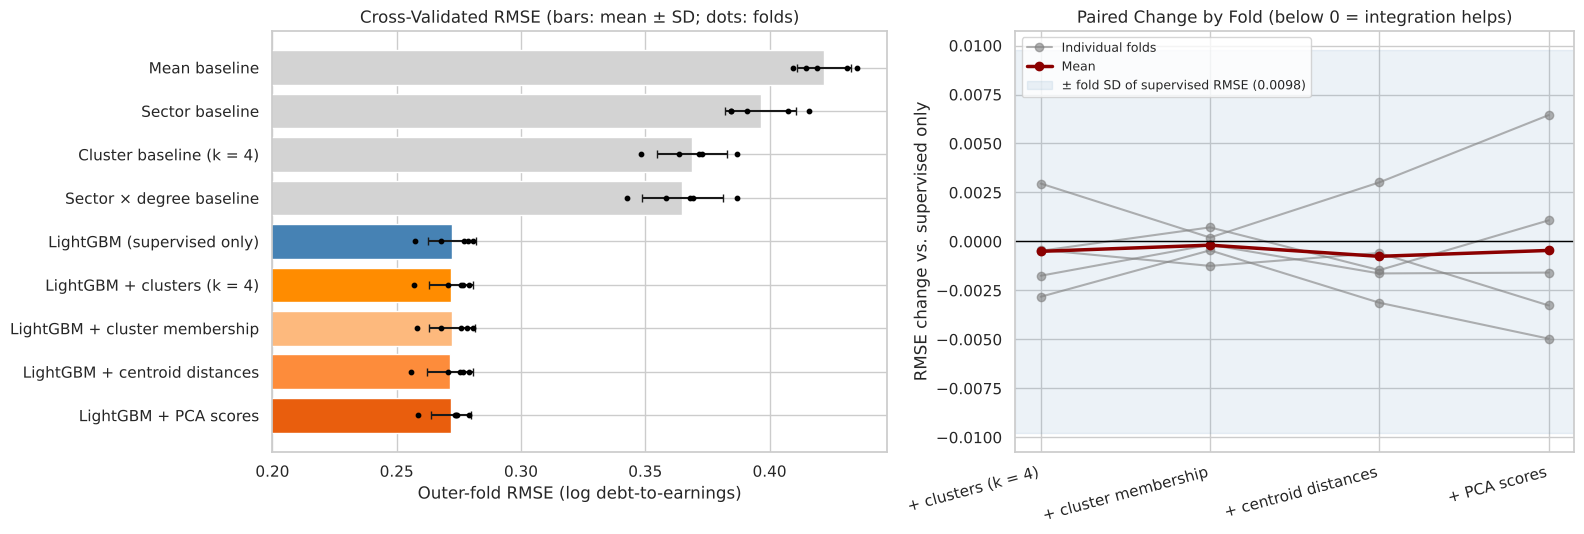

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

colors = ["lightgray"] * 4 + ["steelblue", "darkorange"] + list(sns.color_palette("Oranges", 5)[1:4])
positions = np.arange(len(MODEL_ORDER))[::-1]
axes[0].barh(positions, comparison["rmse_mean"], xerr=comparison["rmse_std"],
             color=colors, capsize=3)
for pos, name in zip(positions, MODEL_ORDER):
    axes[0].scatter(rmse_by_fold[name], np.full(N_FOLDS, pos), color="black", s=10, zorder=3)
axes[0].set_yticks(positions, MODEL_ORDER)
axes[0].set_xlim(0.2, comparison["rmse_mean"].max() * 1.06)
axes[0].set_xlabel("Outer-fold RMSE (log debt-to-earnings)")
axes[0].set_title("Cross-Validated RMSE (bars: mean ± SD; dots: folds)")

for fold in range(N_FOLDS):
    axes[1].plot(diff.columns, diff.loc[fold], marker="o", color="gray", alpha=0.6,
                 label="Individual folds" if fold == 0 else None)
axes[1].plot(diff.columns, diff.mean(), marker="o", color="darkred", lw=2.5, label="Mean")
base_sd = rmse_by_fold[BASE].std()
axes[1].axhspan(-base_sd, base_sd, color="steelblue", alpha=0.1,
                label=f"± fold SD of supervised RMSE ({base_sd:.4f})")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xticks(range(len(diff.columns)),
                   [c.replace(f"{supervised['model']} + ", "+ ") for c in diff.columns])
plt.setp(axes[1].get_xticklabels(), rotation=15, ha="right")
axes[1].set_ylabel("RMSE change vs. supervised only")
axes[1].set_title("Paired Change by Fold (below 0 = integration helps)")
axes[1].legend(fontsize=9, loc="upper left")

fig.tight_layout()
save_figure(fig, "integration_comparison")
plt.show()

### Is the Difference Real?

**No variant passes the decision rule.** The primary integrated model improves RMSE in four of five folds, but by only 0.0005 on average, while the per-fold differences have a standard deviation of 0.0022 (fold 1 gets 0.0030 *worse*). The paired t-test agrees (p = 0.63). The same holds for membership only (−0.0002 ± 0.0007), centroid distances (−0.0008 ± 0.0023, p = 0.50), and PCA scores (−0.0005 ± 0.0045).

For scale, the shaded band in the right panel is the fold-to-fold SD of the supervised model's own RMSE (0.0098): every change from integration is a small fraction of it, and an order of magnitude smaller than the gap between LightGBM and the linear models in Part A (≈ 0.015).

## 7. Sensitivity Checks

### 7.1 Number of Clusters

k = 4 was chosen in Part B for cluster quality and interpretability, not for
prediction. More clusters give the model a finer partition and more
distances, so the comparison is repeated for k = 2 to 10.

LightGBM + clusters (k = 2)                RMSE 0.2721 ± 0.0088   MAE 0.1983   R² 0.583   (8s)


LightGBM + clusters (k = 3)                RMSE 0.2725 ± 0.0091   MAE 0.1986   R² 0.582   (7s)


LightGBM + clusters (k = 4)                RMSE 0.2718 ± 0.0089   MAE 0.1982   R² 0.584   (7s)


LightGBM + clusters (k = 5)                RMSE 0.2728 ± 0.0094   MAE 0.1987   R² 0.581   (7s)


LightGBM + clusters (k = 6)                RMSE 0.2730 ± 0.0085   MAE 0.1988   R² 0.581   (8s)


LightGBM + clusters (k = 7)                RMSE 0.2733 ± 0.0089   MAE 0.1988   R² 0.580   (8s)


LightGBM + clusters (k = 8)                RMSE 0.2732 ± 0.0089   MAE 0.1984   R² 0.580   (8s)


LightGBM + clusters (k = 9)                RMSE 0.2736 ± 0.0088   MAE 0.1994   R² 0.579   (8s)


LightGBM + clusters (k = 10)               RMSE 0.2735 ± 0.0086   MAE 0.1988   R² 0.579   (9s)


,rmse_mean,rmse_change_mean,rmse_change_sd,folds_improved
k,,,,
2,0.2721,-0.0002,0.0021,3
3,0.2725,0.0002,0.0024,2
4,0.2718,-0.0005,0.0022,4
5,0.2728,0.0005,0.0019,2
6,0.2730,0.0007,0.0025,2
7,0.2733,0.0010,0.0019,2
8,0.2732,0.0009,0.0017,2
9,0.2736,0.0013,0.0032,2
10,0.2735,0.0012,0.0025,2


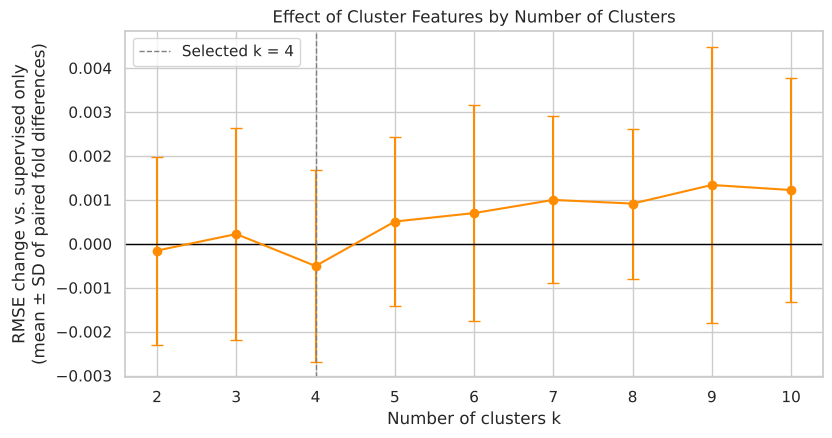

In [9]:
K_VALUES = range(2, 11)
k_rows = []
for k in K_VALUES:
    folds = evaluate(f"{supervised['model']} + clusters (k = {k})", lgbm_model("membership+distances", k),
                     record=False)
    d = folds["rmse"].to_numpy() - rmse_by_fold[BASE].to_numpy()
    k_rows.append({"k": k, "rmse_mean": folds["rmse"].mean(), "rmse_change_mean": d.mean(),
                   "rmse_change_sd": d.std(ddof=1), "folds_improved": int((d < 0).sum())})

k_sensitivity = pd.DataFrame(k_rows).set_index("k")
k_sensitivity.to_csv(RESULTS_DIR / "k_sensitivity.csv")
display(k_sensitivity.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(k_sensitivity.index, k_sensitivity["rmse_change_mean"],
            yerr=k_sensitivity["rmse_change_sd"], marker="o", capsize=4, color="darkorange")
ax.axhline(0, color="black", lw=1)
ax.axvline(SELECTED_K, color="gray", ls="--", lw=1, label=f"Selected k = {SELECTED_K}")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("RMSE change vs. supervised only\n(mean ± SD of paired fold differences)")
ax.set_title("Effect of Cluster Features by Number of Clusters")
ax.legend()
save_figure(fig, "k_sensitivity")
plt.show()

**Changing the number of clusters does not help.** k = 4, the solution chosen in Part B on unsupervised grounds alone, is also the best value here (−0.0005), and k = 2 is the only other value with a negative mean change. From k = 5 upward the cluster features slightly *increase* RMSE (by up to 0.0013 at k = 9): more clusters add more noisy, fold-specific columns that the tuned LightGBM partly overfits. In every case the mean change is smaller than its fold-to-fold SD.

### 7.2 A Linear Model

LightGBM can already form the interactions between degree level, price, and
sector that the clusters summarize. A linear model cannot, so cluster
membership may be more useful to it. The Lasso from Part A (the best linear
model, `alpha` fixed at its tuned value) is compared with and without the
cluster features, which are standardized inside the fold before entering the
linear model.

In [10]:
def make_linear_preprocessor():
    # Same preprocessing as the linear models in 02_supervised_learning.ipynb
    log_numeric = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return [
        ("log", log_numeric, LOG_COLS),
        ("num", numeric, NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ]


def lasso_model(with_clusters):
    transformers = make_linear_preprocessor()
    if with_clusters:
        clusters = make_unsupervised_block("membership+distances", SELECTED_K, PCA_VARIANCE, RANDOM_STATE)
        clusters.steps.append(("scale_out", StandardScaler()))
        transformers.append(("clusters", clusters, CLUSTER_COLS))
    return Pipeline([
        ("prep", ColumnTransformer(transformers)),
        ("model", Lasso(alpha=tuned_params["Lasso"]["alpha"], max_iter=50_000)),
    ])


lasso_rows = {}
for label, with_clusters in [("Lasso (supervised only)", False),
                             (f"Lasso + clusters (k = {SELECTED_K})", True)]:
    lasso_rows[label] = evaluate(label, lasso_model(with_clusters), record=False)

lasso_diff = lasso_rows[f"Lasso + clusters (k = {SELECTED_K})"]["rmse"] - lasso_rows["Lasso (supervised only)"]["rmse"]
lasso_summary = paired_summary(pd.DataFrame({f"Lasso + clusters (k = {SELECTED_K})": lasso_diff.to_numpy()}))
lasso_summary.to_csv(RESULTS_DIR / "linear_model_comparison.csv")
display(lasso_summary.style.format({"rmse_change_mean": "{:+.4f}", "rmse_change_sd": "{:.4f}",
                                    "paired_t": "{:.2f}", "p_value": "{:.3f}"}))
print("Per-fold RMSE change:", lasso_diff.round(4).tolist())

Lasso (supervised only)                    RMSE 0.2898 ± 0.0081   MAE 0.2162   R² 0.527   (0s)


Lasso + clusters (k = 4)                   RMSE 0.2885 ± 0.0084   MAE 0.2149   R² 0.531   (1s)


,rmse_change_mean,rmse_change_sd,folds_improved,n_folds,paired_t,p_value,passes_rule
Lasso + clusters (k = 4),-0.0013,0.0020,4,5,-1.42,0.228,False


Per-fold RMSE change: [0.0016, -0.0016, -0.0034, -0.0003, -0.0025]


**The linear model gains more, but still not enough to pass the rule.** Adding the cluster features lowers Lasso RMSE from 0.2898 to 0.2885 (−0.0013, better in four of five folds, p = 0.23), more than double the gain for LightGBM. This is the expected pattern: cluster membership supplies combinations of degree level, price, and scope that a linear model cannot form, whereas LightGBM already builds them from the raw features. Even with clusters, the Lasso remains well behind LightGBM (0.2885 vs. 0.2723).

### 7.3 Repeated Cross-Validation

Five folds give only five paired differences, so the main comparison is
repeated over five further random 5-fold assignments of the training set
(25 paired differences). Each repetition uses a different seed for the folds,
k-means, and LightGBM.

In [11]:
N_REPEATS = 5
repeat_rows = []
for repeat in range(N_REPEATS):
    seed = RANDOM_STATE + 100 + repeat
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for label, block in [(BASE, None), (INTEGRATED, "membership+distances")]:
        result = cross_validate(lgbm_model(block, random_state=seed), X, y, cv=cv,
                                scoring="neg_root_mean_squared_error")
        for fold, score in enumerate(-result["test_score"]):
            repeat_rows.append({"repeat": repeat, "fold": fold, "model": label, "rmse": score})

repeated = pd.DataFrame(repeat_rows)
repeated.to_csv(RESULTS_DIR / "repeated_cv.csv", index=False)
repeated_wide = repeated.pivot(index=["repeat", "fold"], columns="model", values="rmse")
repeated_diff = repeated_wide[INTEGRATED] - repeated_wide[BASE]

t, p = stats.ttest_1samp(repeated_diff, 0.0)
print(f"Supervised only:  RMSE {repeated_wide[BASE].mean():.4f} ± {repeated_wide[BASE].std():.4f}")
print(f"With clusters:    RMSE {repeated_wide[INTEGRATED].mean():.4f} ± {repeated_wide[INTEGRATED].std():.4f}")
print(f"Paired change:    {repeated_diff.mean():+.4f} ± {repeated_diff.std():.4f} "
      f"(improved in {(repeated_diff < 0).sum()} of {len(repeated_diff)} folds; t = {t:.2f}, p = {p:.3f})")
print("\nMean change per repetition:", repeated_diff.groupby(level="repeat").mean().round(4).tolist())

Supervised only:  RMSE 0.2715 ± 0.0105
With clusters:    RMSE 0.2714 ± 0.0104
Paired change:    -0.0001 ± 0.0016 (improved in 11 of 25 folds; t = -0.18, p = 0.856)

Mean change per repetition: [-0.0002, 0.0003, -0.0005, 0.0004, -0.0003]


**Over 25 paired folds the effect vanishes.** Across five new random fold assignments, the cluster features change RMSE by −0.0001 ± 0.0016, improving 11 of 25 folds (essentially a coin flip; p = 0.86). The mean change per repetition alternates in sign (−0.0002, +0.0003, −0.0005, +0.0004, −0.0003). The small improvement on the shared folds was therefore a property of that particular split, not a reliable gain.

## 8. Where Do the Cluster Features Change the Errors?

Part A found that for-profit and certificate institutions are the hardest to
predict, and Part B found that clusters separate burden most clearly among
for-profits. If the cluster features help anywhere, it should be there. The
table compares out-of-fold RMSE of the two models by sector, predominant
degree, and Part B cluster (full-training-set labels, used for grouping only).

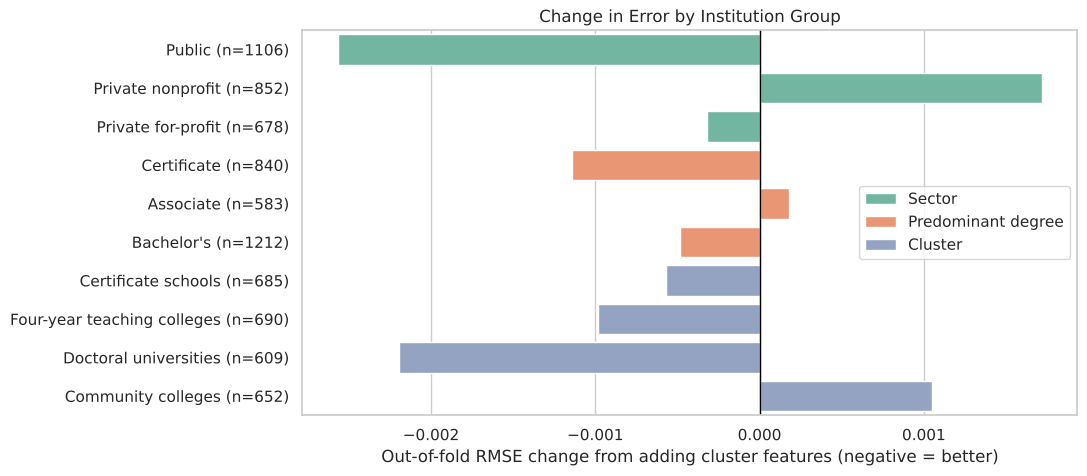

Correlation between the two models' out-of-fold predictions: 0.9934
Mean |difference| between predictions: 0.0258


In [12]:
assignments = pd.read_csv(UNSUPERVISED_DIR / "train_cluster_assignments.csv")
assert (assignments[ID_COL].to_numpy() == train[ID_COL].to_numpy()).all()
train["CLUSTER"] = assignments["cluster_name"].to_numpy()

train["pred_base"] = oof_predictions[BASE]
train["pred_integrated"] = oof_predictions[INTEGRATED]


def group_errors(column, order, min_size=20):
    rows = {}
    for name, sub in train.groupby(column):
        if len(sub) < min_size:
            continue
        rmse_base = root_mean_squared_error(sub[TARGET], sub["pred_base"])
        rmse_int = root_mean_squared_error(sub[TARGET], sub["pred_integrated"])
        rows[name] = {"n": len(sub), "rmse_supervised": rmse_base, "rmse_integrated": rmse_int,
                      "rmse_change": rmse_int - rmse_base,
                      "bias_supervised": (sub[TARGET] - sub["pred_base"]).mean(),
                      "bias_integrated": (sub[TARGET] - sub["pred_integrated"]).mean()}
    return pd.DataFrame(rows).T.reindex([o for o in order if o in rows])


errors_by_group = pd.concat({
    "Sector": group_errors("SECTOR", SECTOR_ORDER),
    "Predominant degree": group_errors("DEGREE", DEGREE_ORDER),
    "Cluster": group_errors("CLUSTER", list(CLUSTER_NAMES.values())),
})
errors_by_group.to_csv(RESULTS_DIR / "errors_by_group.csv")
display(errors_by_group.style.format({
    "n": "{:.0f}", "rmse_supervised": "{:.4f}", "rmse_integrated": "{:.4f}", "rmse_change": "{:+.4f}",
    "bias_supervised": "{:+.4f}", "bias_integrated": "{:+.4f}",
}))

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = errors_by_group.reset_index(names=["grouping", "group"])
plot_df["label"] = plot_df["group"] + " (n=" + plot_df["n"].astype(int).astype(str) + ")"
sns.barplot(data=plot_df, y="label", x="rmse_change", hue="grouping", dodge=False,
            palette="Set2", ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Out-of-fold RMSE change from adding cluster features (negative = better)")
ax.set_ylabel("")
ax.set_title("Change in Error by Institution Group")
ax.legend(title="")
save_figure(fig, "errors_by_group")
plt.show()

prediction_corr = np.corrcoef(train["pred_base"], train["pred_integrated"])[0, 1]
print(f"Correlation between the two models' out-of-fold predictions: {prediction_corr:.4f}")
print(f"Mean |difference| between predictions: "
      f"{(train['pred_base'] - train['pred_integrated']).abs().mean():.4f}")

**The cluster features do not fix the model's weak spots.** For-profit institutions (RMSE 0.354 → 0.353) and certificate institutions (0.341 → 0.340) remain the hardest to predict, with essentially unchanged errors. The largest changes are small improvements for public institutions (−0.0026) and doctoral universities (−0.0022), offset by a slight worsening for private nonprofits (+0.0017) and community colleges (+0.0011). The cluster features modestly reduce the bias in the four-year teaching college (+0.013 → +0.007) and doctoral (−0.012 → −0.007) clusters, but these biases were already small.

The two models' out-of-fold predictions are nearly identical (r = 0.993, mean absolute difference 0.026 on the log scale): adding clusters reshuffles predictions slightly rather than adding a new signal.

## 9. How Much Does the Model Use the Cluster Features?

LightGBM's gain importance measures how much each feature reduces the
training loss across all splits. It is computed for the integrated model
fit in each outer fold, and the share of total gain going to the cluster
features is reported. Cluster indices are not comparable across folds
(k-means numbering is arbitrary), so the cluster features are summarized as
two blocks: membership indicators and centroid distances.

,supervised_features,cluster_membership,centroid_distances,top_supervised_feature,top_supervised_share
fold,,,,,
0,90.2%,0.5%,9.4%,PCTFLOAN,14.4%
1,89.5%,0.9%,9.6%,PCTFLOAN,14.1%
2,90.4%,0.8%,8.9%,PCTFLOAN,14.7%
3,89.6%,1.2%,9.2%,PCTFLOAN,14.3%
4,90.6%,0.5%,8.9%,PCTFLOAN,14.8%


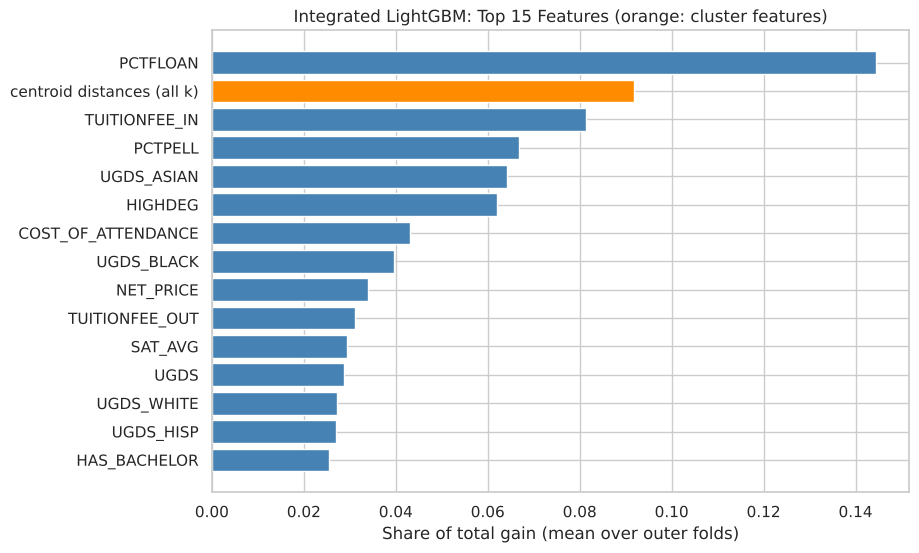

In [13]:
n_base = len(FEATURES)
gain_rows = []
for fold, est in enumerate(fitted_models[INTEGRATED]):
    gain = est.named_steps["model"].booster_.feature_importance(importance_type="gain")
    gain = gain / gain.sum()
    gain_rows.append({
        "fold": fold,
        "supervised_features": gain[:n_base].sum(),
        "cluster_membership": gain[n_base:n_base + SELECTED_K].sum(),
        "centroid_distances": gain[n_base + SELECTED_K:].sum(),
        "top_supervised_feature": FEATURES[int(gain[:n_base].argmax())],
        "top_supervised_share": gain[:n_base].max(),
    })

gain_share = pd.DataFrame(gain_rows).set_index("fold")
gain_share.to_csv(RESULTS_DIR / "cluster_feature_importance.csv")
display(gain_share.style.format({c: "{:.1%}" for c in gain_share.columns if c != "top_supervised_feature"}))

# Per-feature gain averaged over folds, with cluster features pooled into their two blocks
feature_gain = []
for est in fitted_models[INTEGRATED]:
    g = est.named_steps["model"].booster_.feature_importance(importance_type="gain")
    g = g / g.sum()
    s = pd.Series(g[:n_base], index=FEATURES)
    s["cluster membership (all k)"] = g[n_base:n_base + SELECTED_K].sum()
    s["centroid distances (all k)"] = g[n_base + SELECTED_K:].sum()
    feature_gain.append(s)
feature_gain = pd.concat(feature_gain, axis=1).mean(axis=1).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(feature_gain.index[::-1], feature_gain[::-1],
        color=["darkorange" if "cluster" in c or "centroid" in c else "steelblue"
               for c in feature_gain.index[::-1]])
ax.set_xlabel("Share of total gain (mean over outer folds)")
ax.set_title("Integrated LightGBM: Top 15 Features (orange: cluster features)")
save_figure(fig, "cluster_feature_importance")
plt.show()

**LightGBM does use the cluster features, but mainly as substitutes for features it already has.** Around 10% of the total gain goes to cluster features in every fold, almost all of it to the centroid distances (≈ 9%) rather than membership (≈ 1%). The distances are continuous summaries of degree level, price, and composition, so the trees split on them in place of the original columns. `PCTFLOAN` remains the single most important feature (≈ 14% of gain). Because the splits move from the original features to the distances without improving validation error, the gain share measures redundancy, not added information.

## 10. Integration Decision and Saved Outputs

The decision rule from the introduction is applied to the primary integrated
model on the shared folds and checked against the repeated cross-validation.
The pipeline carried forward to `05_final_evaluation.ipynb` is recorded in
`results/04_integration/integration_decision.json`, together with the
settings needed to rebuild either arm with `src/integration.py`.

In [14]:
primary = comparison.loc[INTEGRATED]
repeated_passes = bool(-repeated_diff.mean() > repeated_diff.std()
                       and (repeated_diff < 0).mean() >= 0.8)
adopt_clusters = bool(primary["passes_rule"]) and repeated_passes

decision = {
    "adopt_cluster_features": adopt_clusters,
    "final_pipeline": INTEGRATED if adopt_clusters else BASE,
    "rule": ("adopt only if the mean paired RMSE improvement exceeds the SD of the paired "
             "fold differences and the integrated model improves in at least 80% of folds"),
    "supervised_model": supervised["model"],
    "hyperparameters": supervised["hyperparameters"],
    "features": FEATURES,
    "unsupervised_block": "membership+distances" if adopt_clusters else None,
    "cluster_columns": CLUSTER_COLS,
    "n_clusters": SELECTED_K,
    "pca_variance": PCA_VARIANCE,
    "random_state": RANDOM_STATE,
    "shared_folds": {
        "supervised_rmse_mean": round(float(comparison.loc[BASE, "rmse_mean"]), 4),
        "integrated_rmse_mean": round(float(primary["rmse_mean"]), 4),
        "rmse_change_mean": round(float(primary["rmse_change_mean"]), 4),
        "rmse_change_sd": round(float(primary["rmse_change_sd"]), 4),
        "folds_improved": int(primary["folds_improved"]),
        "n_folds": int(primary["n_folds"]),
    },
    "repeated_cv": {
        "n_repeats": N_REPEATS,
        "rmse_change_mean": round(float(repeated_diff.mean()), 4),
        "rmse_change_sd": round(float(repeated_diff.std()), 4),
        "folds_improved": int((repeated_diff < 0).sum()),
        "n_folds": int(len(repeated_diff)),
    },
    "best_variant_on_shared_folds": str(paired["rmse_change_mean"].astype(float).idxmin()),
    "build": ("src.integration.make_integrated_model(make_lgbm(hyperparameters), features, "
              "cluster_columns, block=unsupervised_block, n_clusters=n_clusters, "
              "pca_variance=pca_variance, random_state=random_state)"),
}
with open(RESULTS_DIR / "integration_decision.json", "w") as f:
    json.dump(decision, f, indent=2)

oof_out = pd.DataFrame(oof_predictions)[MODEL_ORDER]
oof_out.insert(0, "fold", fold_id)
oof_out.insert(0, TARGET, y.to_numpy())
oof_out.insert(0, ID_COL, train[ID_COL].to_numpy())
oof_out.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

print(json.dumps({k: decision[k] for k in ["adopt_cluster_features", "final_pipeline",
                                           "shared_folds", "repeated_cv"]}, indent=2))
print("\nSaved:")
for path in sorted(RESULTS_DIR.glob("*")):
    print(" ", path.relative_to(PROJECT_ROOT).as_posix())

{
  "adopt_cluster_features": false,
  "final_pipeline": "LightGBM (supervised only)",
  "shared_folds": {
    "supervised_rmse_mean": 0.2723,
    "integrated_rmse_mean": 0.2718,
    "rmse_change_mean": -0.0005,
    "rmse_change_sd": 0.0022,
    "folds_improved": 4,
    "n_folds": 5
  },
  "repeated_cv": {
    "n_repeats": 5,
    "rmse_change_mean": -0.0001,
    "rmse_change_sd": 0.0016,
    "folds_improved": 11,
    "n_folds": 25
  }
}

Saved:
  results/04_integration/cluster_feature_importance.csv
  results/04_integration/cv_scores_by_fold.csv
  results/04_integration/errors_by_group.csv
  results/04_integration/integration_comparison.csv
  results/04_integration/integration_decision.json
  results/04_integration/k_sensitivity.csv
  results/04_integration/linear_model_comparison.csv
  results/04_integration/oof_predictions.csv
  results/04_integration/repeated_cv.csv


## Summary

### Findings

1. **The institutional types are informative about burden on their own.** Out of sample, a model that predicts each institution's cluster mean reaches RMSE 0.369 (R² = 0.24), far better than sector alone (0.397, R² = 0.12) and close to the ten sector × degree cells (0.365, R² = 0.25), using only four groups formed without the outcome.
2. **They add no reliable predictive information to the supervised model.** Adding cluster membership and centroid distances, refit inside every fold, changes LightGBM's RMSE from 0.2723 to 0.2718 (−0.0005 ± 0.0022 across folds). Over 25 repeated folds the change is −0.0001 ± 0.0016, with improvement in 11 of 25 folds. Membership only, distances only, PCA scores, and k = 2 to 10 give the same result.
3. **The cluster information is redundant with the original features.** LightGBM assigns about 10% of its gain to the centroid distances, yet the predictions barely change (r = 0.993). A linear model, which cannot form the interactions that the clusters summarize, gains more (−0.0013) but still not reliably.
4. **The hard cases stay hard.** For-profit and certificate institutions, where Part A errors are largest, are not helped by the cluster features.

### Decision

The improvement is smaller than the fold-to-fold variation in every check, so **the cluster features are not adopted**. `05_final_evaluation.ipynb` will evaluate the supervised-only LightGBM pipeline on the held-out test set; the integrated pipeline can be rebuilt from `integration_decision.json` with `src/integration.py` if the final notebook reports it as a comparison.

This is a substantive result, not a failed experiment: the clusters are a compact, interpretable description of institutional structure (Part B), and this notebook shows that structure is already captured by the institutional characteristics the supervised model uses.

### Limitations

- Hyperparameters were tuned in Part A for the supervised features and were not re-tuned with the cluster features. Re-tuning could change the comparison slightly but would be unlikely to overcome a difference this small relative to its variability.
- The comparison uses training-set cross-validation only; the held-out test set remains untouched.
- Gain importance is computed on training data and reflects how the trees split, not out-of-sample value.

### Outputs

| Output | Location |
|---|---|
| Integration decision and settings to rebuild either pipeline | `results/04_integration/integration_decision.json` |
| Model comparison with paired fold statistics | `results/04_integration/integration_comparison.csv`, `cv_scores_by_fold.csv` |
| k sensitivity, linear-model, and repeated-CV checks | `results/04_integration/k_sensitivity.csv`, `linear_model_comparison.csv`, `repeated_cv.csv` |
| Errors by group and cluster-feature importance | `results/04_integration/errors_by_group.csv`, `cluster_feature_importance.csv` |
| Out-of-fold predictions for every model | `results/04_integration/oof_predictions.csv` |
| Integration pipeline builders | `src/integration.py` |
| Figures | `figures/04_integration/*.png` |